In [13]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import loadmat
from pathlib import Path
import matplotlib as mpl
import matplotlib.image as mpimg
from pdf2image import convert_from_path
from matplotlib.lines import Line2D
from matplotlib.legend_handler import HandlerTuple
from matplotlib.patches import FancyArrowPatch
from math import ceil

# ============================================================
# GLOBAL STYLE / EXPORT SETTINGS
# ============================================================
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Arial']
plt.rcParams['mathtext.fontset'] = 'custom'
plt.rcParams['mathtext.rm'] = 'Arial'
plt.rcParams['mathtext.it'] = 'Arial:italic'
plt.rcParams['mathtext.bf'] = 'Arial:bold'
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['ps.fonttype'] = 42

# ============================================================
# DATA DIRECTORIES
# Define all data paths used throughout the notebook
# ============================================================

DATA_DIR_40 = Path.cwd().parent/ "all sims & analysis" / "lambda_S_1_J_40" / "sim_analysis_MATLAB"

DATA_DIR_50  = Path.cwd().parent/ "all sims & analysis" / "lambda_S_1_J_50" / "sim_analysis_MATLAB"

DATA_DIR_60 = Path.cwd().parent/ "all sims & analysis" / "lambda_S_1_J_60" / "sim_analysis_MATLAB"

# Block tags used across all datasets
BLOCK_TAGS = ['06', '07', '08', '09', '1']

# Force scale factors for different conditions
FORCE_SCALE_FACTORS = [0.6, 0.7, 0.8, 0.9, 1.0]

# Color scheme for consistent plotting
FORCE_COLORS = {
    0.6: (0.00, 0.45, 0.70),  # blue
    0.7: (0.80, 0.40, 0.00),  # orange
    0.8: (0.00, 0.00, 0.00),  # black
    0.9: (0.35, 0.70, 0.90),  # light blue
    1.0: (0.90, 0.60, 0.00),  # mustard
}

STIFFNESS_COLORS = [
    (0.00, 0.45, 0.70),  # blue
    (0.80, 0.40, 0.00),  # orange
    (0.00, 0.00, 0.00),  # black
]

print("Configuration loaded successfully")
print(f"Data directories: {DATA_DIR_40.name}, {DATA_DIR_50.name}, {DATA_DIR_60.name}")

Configuration loaded successfully
Data directories: sim_analysis_MATLAB, sim_analysis_MATLAB, sim_analysis_MATLAB


## Aspiration Length Time Course

The following functions create plots of aspiration length ($L_p$) over time 
for different experimental datasets. Each dataset contains 5 force conditions 
(scale factors: 0.6, 0.7, 0.8, 0.9, 1.0) with error bars showing SEM across 
experimental blocks.

- `subplot_Lp08`: Full plot with y-axis label
- `subplot_Lp1`: Without y-axis label (for multi-panel layouts)
- `subplot_Lp12`: With legend showing force scale factors

In [14]:
def _plot_aspiration_timecourse(ax, data_dir, show_ylabel=True, show_legend=False):

    colors = list(FORCE_COLORS.values())

    # Load data and plot
    plot_handles = []
    
    for i, tag in enumerate(BLOCK_TAGS):
        matfile = data_dir / f'block_{tag}_results.mat'
        data = loadmat(matfile)

        time = np.squeeze(data[f'timeCommon_{tag}'])
        mean = np.squeeze(data[f'mean_{tag}'])
        sem = np.squeeze(data[f'sem_{tag}'])

        # Plot SEM as shaded region
        ax.fill_between(
            time,
            mean + sem,
            mean - sem,
            color=colors[i],
            alpha=0.3,
            linewidth=0
        )

        # Plot mean line
        h, = ax.plot(
            time,
            mean,
            '-',
            color=colors[i],
            linewidth=2
        )
        plot_handles.append(h)

    # Format axes
    ax.set_xlim(0, 120)
    ax.set_ylim(0, 140)
    ax.set_xticks([0, 40, 80, 120])
    ax.set_xlabel('Time (s)', fontsize=20)
    
    if show_ylabel:
        ax.set_ylabel(r'$L_p$ ($\mu$m)', fontsize=20)
    
    ax.tick_params(axis='both', direction='out', labelsize=18, width=1.2)
    ax.grid(False)
    
    for spine in ax.spines.values():
        spine.set_linewidth(1.2)

    # Add legend if requested
    if show_legend:
        legend_labels = [f"{x:.1f}" for x in FORCE_SCALE_FACTORS]
        blank_handle = Line2D([], [], linestyle='none')

        legend_handles = [
            blank_handle,
            plot_handles[2],   # 0.8
            plot_handles[0],   # 0.6
            plot_handles[3],   # 0.9
            plot_handles[1],   # 0.7
            plot_handles[4],   # 1.0
        ]

        legend_text = [
            '',
            legend_labels[2],  # 0.8
            legend_labels[0],  # 0.6
            legend_labels[3],  # 0.9
            legend_labels[1],  # 0.7
            legend_labels[4],  # 1.0
        ]

        leg = ax.legend(
            legend_handles,
            legend_text,
            loc='upper left',
            bbox_to_anchor=(0.01, 1.05),
            ncol=3,
            frameon=False,
            fontsize=18,
            handlelength=2.8,
            handletextpad=0.5,
            columnspacing=1.2,
            labelspacing=0.5,
        )

        for line in leg.get_lines():
            line.set_linewidth(7)

        # Add legend header
        ax.text(
            0.06, 0.97,
            r'$F_{\mathrm{eff}}$ ($\lambda_D$)',
            transform=ax.transAxes,
            fontsize=18,
            ha='left',
            va='top'
        )


def subplot_Lp40(ax):
    """
    Plot aspiration length vs time for J = 40.
    
    Shows mean ± SEM across experimental blocks to demonstrate 
    aspiration variance due to force differences.
    """
    _plot_aspiration_timecourse(
        ax, 
        data_dir=DATA_DIR_40,
        show_ylabel=True
    )


def subplot_Lp50(ax):
    """
    Plot aspiration length vs time for J = 50.
    
    Similar to subplot_Lp40 but without y-axis label (for multi-panel figure).
    """
    _plot_aspiration_timecourse(
        ax, 
        data_dir=DATA_DIR_50,
        show_ylabel=False
    )


def subplot_Lp60(ax):
    """
    Plot aspiration length vs time for J = 60.
    
    Includes a custom legend showing effective force (F_eff) scale factors.
    """
    _plot_aspiration_timecourse(
        ax, 
        data_dir=DATA_DIR_60,
        show_ylabel=False,
        show_legend=True
    )

## Elastic Modulus Estimation

Plots normalized aspiration length vs applied force for three cell stiffness conditions. Linear fits are used to extract elastic modulus values, with error bars showing confidence intervals of viscoelastic model fits.

In [19]:
def subplot_elasticity(ax):

    # Force offsets for each stiffness condition
    force_offset_40 = 0.26
    force_offset_50 = 0.17
    force_offset_60 = 0.0
    
    force_60 = np.array(FORCE_SCALE_FACTORS) - force_offset_60
    force_50 = np.array(FORCE_SCALE_FACTORS) - force_offset_50
    force_40 = np.array(FORCE_SCALE_FACTORS) - force_offset_40

    # Load aspiration length data for each condition
    def load_aspiration_data(data_dir, block_tags):
        """loading mean and confidence intervals for aspiration length."""
        mean_values = []
        lower_bounds = []
        upper_bounds = []

        for tag in block_tags:
            matfile = data_dir / f'block_{tag}_results.mat'
            data = loadmat(matfile)

            upper_bounds.append(np.squeeze(data[f'higher_L_p_{tag}']))
            lower_bounds.append(np.squeeze(data[f'lower_L_p_{tag}']))
            mean_values.append(np.squeeze(data[f'mean_L_p_{tag}']))

        return np.array(mean_values), np.array(lower_bounds), np.array(upper_bounds)

    Lp_mean_40, Lp_lower_40, Lp_upper_40 = load_aspiration_data(DATA_DIR_40, BLOCK_TAGS)
    Lp_mean_50, Lp_lower_50, Lp_upper_50 = load_aspiration_data(DATA_DIR_50, BLOCK_TAGS)
    Lp_mean_60, Lp_lower_60, Lp_upper_60 = load_aspiration_data(DATA_DIR_60, BLOCK_TAGS)

    # Normalize by spheroid radius
    Rp = 111.8  # spheroid radius (μm)

    norm_L_60 = Lp_mean_60 / Rp
    norm_L_60_lower = Lp_lower_60 / Rp
    norm_L_60_upper = Lp_upper_60 / Rp

    norm_L_50 = Lp_mean_50 / Rp
    norm_L_50_lower = Lp_lower_50 / Rp
    norm_L_50_upper = Lp_upper_50 / Rp

    norm_L_40 = Lp_mean_40 / Rp
    norm_L_40_lower = Lp_lower_40 / Rp
    norm_L_40_upper = Lp_upper_40 / Rp

    # Calculate error bars
    x_err_neg_60 = norm_L_60 - norm_L_60_lower
    x_err_pos_60 = norm_L_60_upper - norm_L_60

    x_err_neg_50 = norm_L_50 - norm_L_50_lower
    x_err_pos_50 = norm_L_50_upper - norm_L_50

    x_err_neg_40 = norm_L_40 - norm_L_40_lower
    x_err_pos_40 = norm_L_40_upper - norm_L_40

    # Linear fits
    fit_60 = np.polyfit(norm_L_60, force_60, 1)
    fit_50 = np.polyfit(norm_L_50, force_50, 1)
    fit_40 = np.polyfit(norm_L_40, force_40, 1)

    x_fit_60 = np.linspace(norm_L_60.min(), norm_L_60.max(), 200)
    y_fit_60 = np.polyval(fit_60, x_fit_60)

    x_fit_50 = np.linspace(norm_L_50.min(), norm_L_50.max(), 200)
    y_fit_50 = np.polyval(fit_50, x_fit_50)

    x_fit_40 = np.linspace(norm_L_40.min(), norm_L_40.max(), 200)
    y_fit_40 = np.polyval(fit_40, x_fit_40)

    # Calculate elastic modulus
    correction_factor = 3 / (4.2 * np.pi)
    modulus_60 = fit_60[0] * correction_factor
    modulus_50 = fit_50[0] * correction_factor
    modulus_40 = fit_40[0] * correction_factor

    print(f"Elastic modulus for J = -40: E = {modulus_60:.6f}")
    print(f"Elastic modulus for J = -50: E = {modulus_50:.6f}")
    print(f"Elastic modulus for J = -60: E = {modulus_40:.6f}")

    # Plot styling
    markers = ['o', 's', '^']
    linestyles = ['-', '--', ':']

    data_x = [norm_L_60, norm_L_50, norm_L_40]
    data_y = [force_60, force_50, force_40]
    err_neg = [x_err_neg_60, x_err_neg_50, x_err_neg_40]
    err_pos = [x_err_pos_60, x_err_pos_50, x_err_pos_40]
    fit_x = [x_fit_60, x_fit_50, x_fit_40]
    fit_y = [y_fit_60, y_fit_50, y_fit_40]
    labels = [r'$-60$', '$-50$', '$-40$']

    # Plot data and fits
    handles = []
    for i in range(3):
        # Fit line
        ax.plot(fit_x[i], fit_y[i],
                linestyle=linestyles[i],
                linewidth=1.8,
                color=STIFFNESS_COLORS[i])

        # Error bars
        ax.errorbar(data_x[i], data_y[i],
                    xerr=[err_neg[i], err_pos[i]],
                    fmt='none',
                    ecolor=STIFFNESS_COLORS[i],
                    elinewidth=1.2,
                    capsize=6)

        # Data points
        h, = ax.plot(data_x[i], data_y[i],
                     marker=markers[i],
                     linestyle='none',
                     markersize=11,
                     markerfacecolor=STIFFNESS_COLORS[i],
                     markeredgecolor='white',
                     markeredgewidth=1.2,
                     label=labels[i])
        handles.append(h)

    # Format axes
    ax.set_xlabel(r'$L_p/R$', fontsize=20)
    ax.set_ylabel(r'$\Delta F$ ($\Delta \lambda_D$)', fontsize=20)
    ax.tick_params(axis='both', direction='out', width=1.2, labelsize=18)
    
    for spine in ['top', 'right']:
        ax.spines[spine].set_visible(False)
    for spine in ['left', 'bottom']:
        ax.spines[spine].set_linewidth(1.2)

    # Legend (order: -40, -50, -60)
    ax.legend(
        handles=handles[::-1],
        loc='upper left',
    bbox_to_anchor=(-0.05, 0.92),
        frameon=False,
        fontsize=18,
        handletextpad=0.2
    )

    # Legend title
    ax.text(
        0.02, 1.0,
        r'cell-cell' + '\nadhesion ($J$)',
        transform=ax.transAxes,
        fontsize=18,
        ha='left',
        va='top'
    )

## Spring Constant k vs Cell-Cell Adhesion

Plots the fitted spring constant $k$ across three cell-cell adhesion conditions ($J$ = -40, -50, -60) for five aspiration force levels. Each point represents a specific force condition, with error bars showing confidence intervals of the viscoelastic model fit. Gray lines connect matching force conditions across stiffness levels, and horizontal lines indicate group means.

In [23]:
def subplot_k_all(ax):

    # Force values for each adhesion
    force_40 = np.array(FORCE_SCALE_FACTORS)
    force_50 = np.array(FORCE_SCALE_FACTORS)
    force_60 = np.array(FORCE_SCALE_FACTORS)

    # Load k parameter data for each condition
    def load_k_data(data_dir, block_tags):
        """loading mean and confidence intervals for parameter k."""
        mean_values = []
        lower_bounds = []
        upper_bounds = []

        for tag in block_tags:
            matfile = data_dir / f'block_{tag}_results.mat'
            data = loadmat(matfile)

            upper_bounds.append(np.squeeze(data[f'higher_k_{tag}']))
            lower_bounds.append(np.squeeze(data[f'lower_k_{tag}']))
            mean_values.append(np.squeeze(data[f'mean_k_{tag}']))

        return np.array(mean_values), np.array(lower_bounds), np.array(upper_bounds)

    k_mean_40, k_lower_40, k_upper_40 = load_k_data(DATA_DIR_40, BLOCK_TAGS)
    k_mean_50, k_lower_50, k_upper_50 = load_k_data(DATA_DIR_50, BLOCK_TAGS)
    k_mean_60, k_lower_60, k_upper_60 = load_k_data(DATA_DIR_60, BLOCK_TAGS)

    # Group positioning
    center_spacing = 0.7
    x_pos = np.array([1, 1 + center_spacing, 1 + 2 * center_spacing])

    # Calculate group statistics
    data_groups = [k_mean_40, k_mean_50, k_mean_60]
    group_means = np.array([np.mean(d) for d in data_groups])
    group_maxes = np.array([np.max(d) for d in data_groups])
    group_mins = np.array([np.min(d) for d in data_groups])

    print(f"Mean k (J = -40): {group_means[0]:.6f}")
    print(f"Mean k (J = -50): {group_means[1]:.6f}")
    print(f"Mean k (J = -60): {group_means[2]:.6f}")

    # Plot background boxes and mean lines
    box_width = 0.4
    for i in range(3):
        # Gray background box
        ax.add_patch(
            plt.Rectangle(
                (x_pos[i] - box_width / 2, np.min(data_groups[i])),
                box_width,
                np.max(data_groups[i]) - np.min(data_groups[i]),
                facecolor=(0.96, 0.96, 0.96),
                edgecolor='none',
                zorder=0
            )
        )

        # Mean line
        ax.plot(
            [x_pos[i] - box_width / 2, x_pos[i] + box_width / 2],
            [np.mean(data_groups[i]), np.mean(data_groups[i])],
            color=(0.2, 0.2, 0.2),
            linewidth=2.5,
            alpha=0.5,
            zorder=1
        )

    # Connect matching force conditions across groups
    common_forces = np.intersect1d(np.intersect1d(force_40, force_50), force_60)

    for force_val in common_forces:
        k_values = [
            k_mean_40[np.isclose(force_40, force_val)][0],
            k_mean_50[np.isclose(force_50, force_val)][0],
            k_mean_60[np.isclose(force_60, force_val)][0]
        ]
        ax.plot(x_pos, k_values, '-', color=(0.8, 0.8, 0.8), linewidth=1, zorder=1)

    # Plot data points with error bars
    force_sets = [force_40, force_50, force_60]
    k_sets = [k_mean_40, k_mean_50, k_mean_60]
    k_low_sets = [k_lower_40, k_lower_50, k_lower_60]
    k_high_sets = [k_upper_40, k_upper_50, k_upper_60]

    all_forces = np.unique(np.concatenate([force_40, force_50, force_60]))
    legend_handles = []
    legend_labels = []

    for force_val in all_forces:
        col = FORCE_COLORS[round(float(force_val), 2)]

        # Create legend handle (once per force level)
        h = plt.Line2D(
            [0], [0],
            marker='o',
            linestyle='none',
            markerfacecolor=col,
            markeredgecolor=(0.3, 0.3, 0.3),
            markersize=10
        )
        legend_handles.append(h)
        legend_labels.append(f"{force_val:.1f}")

        # Plot points for each group
        for group_i in range(3):
            forces = force_sets[group_i]
            k_vals = k_sets[group_i]
            k_low = k_low_sets[group_i]
            k_high = k_high_sets[group_i]

            idx = np.where(np.isclose(forces, force_val))[0]

            if len(idx) > 0:
                idx = idx[0]
                y = k_vals[idx]
                err_low = y - k_low[idx]
                err_high = k_high[idx] - y

                # Error bars
                ax.errorbar(
                    x_pos[group_i],
                    y,
                    yerr=[[err_low], [err_high]],
                    linestyle='none',
                    color=(0.45, 0.45, 0.45),
                    linewidth=1.1,
                    capsize=7,
                    zorder=2
                )

                # Data point
                ax.plot(
                    x_pos[group_i],
                    y,
                    'o',
                    markerfacecolor=col,
                    markeredgecolor=(0.3, 0.3, 0.3),
                    markersize=11,
                    zorder=3
                )
                
#         legend_handles = legend_handles[::-1]
#     legend_labels = legend_labels[::-1]

    ax.legend(
        legend_handles,
        legend_labels,
        title=r'$F_{eff}$ ($\lambda_D$)',
        loc='upper left',
        bbox_to_anchor=(0.0, 1.0),
        frameon=False,
        fontsize=18,
        title_fontsize=18,
        handletextpad=0.2
    )

    # Format axes
    ax.set_xticks(x_pos)
    ax.set_xticklabels([r'$-40$', '$-50$', '$-60$'])
    ax.set_xlabel(r'$J$', fontsize=20)
    ax.set_ylabel(r'$k$ (fitted)', fontsize=20)
    ax.set_xlim(x_pos.min() - 0.5, x_pos.max() + 0.5)
    ax.tick_params(axis='both', direction='out', labelsize=18, width=1.2)

    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_linewidth(1.2)
    ax.spines['bottom'].set_linewidth(1.2)
    ax.grid(False)

## Retardation Time $\tau$ vs Cell-Cell Adhesion

Plots the fitted retardation time $\tau$ across three cell-cell adhesion conditions ($J$ = -40, -50, -60) for five aspiration force levels. Each point represents a specific force condition, with error bars showing confidence intervals of the viscoelastic model fit. Gray lines connect matching force conditions across stiffness levels, and horizontal lines indicate group means.

In [24]:
def subplot_tau_lambda(ax):

    # Force values for each adhesion
    force_40 = np.array(FORCE_SCALE_FACTORS)
    force_50 = np.array(FORCE_SCALE_FACTORS)
    force_60 = np.array(FORCE_SCALE_FACTORS)

    # Load tau parameter data for each condition
    def load_tau_data(data_dir, block_tags):
        """loading mean and confidence intervals for parameter tau."""
        mean_values = []
        lower_bounds = []
        upper_bounds = []

        for tag in block_tags:
            matfile = data_dir / f'block_{tag}_results.mat'
            data = loadmat(matfile)

            upper_bounds.append(np.squeeze(data[f'higher_tau_{tag}']))
            lower_bounds.append(np.squeeze(data[f'lower_tau_{tag}']))
            mean_values.append(np.squeeze(data[f'mean_tau_{tag}']))

        return np.array(mean_values), np.array(lower_bounds), np.array(upper_bounds)

    tau_mean_40, tau_lower_40, tau_upper_40 = load_tau_data(DATA_DIR_40, BLOCK_TAGS)
    tau_mean_50, tau_lower_50, tau_upper_50 = load_tau_data(DATA_DIR_50, BLOCK_TAGS)
    tau_mean_60, tau_lower_60, tau_upper_60 = load_tau_data(DATA_DIR_60, BLOCK_TAGS)

    # Group positioning
    center_spacing = 0.7
    x_pos = np.array([1, 1 + center_spacing, 1 + 2 * center_spacing])

    # Calculate group statistics
    data_groups = [tau_mean_40, tau_mean_50, tau_mean_60]
    group_means = np.array([np.mean(d) for d in data_groups])
    group_maxes = np.array([np.max(d) for d in data_groups])
    group_mins = np.array([np.min(d) for d in data_groups])

    print(f"Mean τ (J = -40): {group_means[0]:.6f}")
    print(f"Mean τ (J = -50): {group_means[1]:.6f}")
    print(f"Mean τ (J = -60): {group_means[2]:.6f}")

    # Plot background boxes and mean lines
    box_width = 0.4
    for i in range(3):
        # Gray background box
        ax.add_patch(
            plt.Rectangle(
                (x_pos[i] - box_width / 2, np.min(data_groups[i])),
                box_width,
                np.max(data_groups[i]) - np.min(data_groups[i]),
                facecolor=(0.96, 0.96, 0.96),
                edgecolor='none',
                zorder=0
            )
        )

        # Mean line
        ax.plot(
            [x_pos[i] - box_width / 2, x_pos[i] + box_width / 2],
            [np.mean(data_groups[i]), np.mean(data_groups[i])],
            color=(0.2, 0.2, 0.2),
            linewidth=2.5,
            alpha=0.5,
            zorder=1
        )

    # Connect matching force conditions across groups
    common_forces = np.intersect1d(np.intersect1d(force_40, force_50), force_60)

    for force_val in common_forces:
        tau_values = [
            tau_mean_40[np.isclose(force_40, force_val)][0],
            tau_mean_50[np.isclose(force_50, force_val)][0],
            tau_mean_60[np.isclose(force_60, force_val)][0]
        ]
        ax.plot(x_pos, tau_values, '-', color=(0.8, 0.8, 0.8), linewidth=1, zorder=1)

    # Plot data points with error bars
    force_sets = [force_40, force_50, force_60]
    tau_sets = [tau_mean_40, tau_mean_50, tau_mean_60]
    tau_low_sets = [tau_lower_40, tau_lower_50, tau_lower_60]
    tau_high_sets = [tau_upper_40, tau_upper_50, tau_upper_60]

    all_forces = np.unique(np.concatenate([force_40, force_50, force_60]))
    legend_handles = []
    legend_labels = []

    for force_val in all_forces:
        col = FORCE_COLORS[round(float(force_val), 2)]

        # Create legend handle (once per force level)
        h = plt.Line2D(
            [0], [0],
            marker='o',
            linestyle='none',
            markerfacecolor=col,
            markeredgecolor=(0.3, 0.3, 0.3),
            markersize=10
        )
        legend_handles.append(h)
        legend_labels.append(f"{force_val:.1f}")

        # Plot points for each group
        for group_i in range(3):
            forces = force_sets[group_i]
            tau_vals = tau_sets[group_i]
            tau_low = tau_low_sets[group_i]
            tau_high = tau_high_sets[group_i]

            idx = np.where(np.isclose(forces, force_val))[0]

            if len(idx) > 0:
                idx = idx[0]
                y = tau_vals[idx]
                err_low = y - tau_low[idx]
                err_high = tau_high[idx] - y

                # Error bars
                ax.errorbar(
                    x_pos[group_i],
                    y,
                    yerr=[[err_low], [err_high]],
                    linestyle='none',
                    color=(0.45, 0.45, 0.45),
                    linewidth=1.1,
                    capsize=7,
                    zorder=2
                )

                # Data point
                ax.plot(
                    x_pos[group_i],
                    y,
                    'o',
                    markerfacecolor=col,
                    markeredgecolor=(0.3, 0.3, 0.3),
                    markersize=11,
                    zorder=3
                )

    # Format axes
    ax.set_xticks(x_pos)
    ax.set_xticklabels([r'$-40$', '$-50$', '$-60$'])
    ax.set_xlabel(r'$J$', fontsize=20)
    ax.set_ylabel(r'$\tau$ (fitted)', fontsize=20)
    ax.set_xlim(x_pos.min() - 0.5, x_pos.max() + 0.5)
    ax.tick_params(axis='both', direction='out', labelsize=18, width=1.2)

    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_linewidth(1.2)
    ax.spines['bottom'].set_linewidth(1.2)
    ax.grid(False)

## Figure Assembly

Creates a multi-panel figure with:
- **Top row (a)**: Three time-course plots showing aspiration length across different cell stiffness conditions
- **Bottom row (b-d)**: Analysis plots showing viscoelastic parameters (k, τ) and elastic modulus relationships

Mean k (J = -40): 0.008057
Mean k (J = -50): 0.010003
Mean k (J = -60): 0.013557
Mean τ (J = -40): 7.059772
Mean τ (J = -50): 8.112046
Mean τ (J = -60): 13.921374
Elastic modulus for J = -40: E = 0.520353
Elastic modulus for J = -50: E = 0.419938
Elastic modulus for J = -60: E = 0.291429


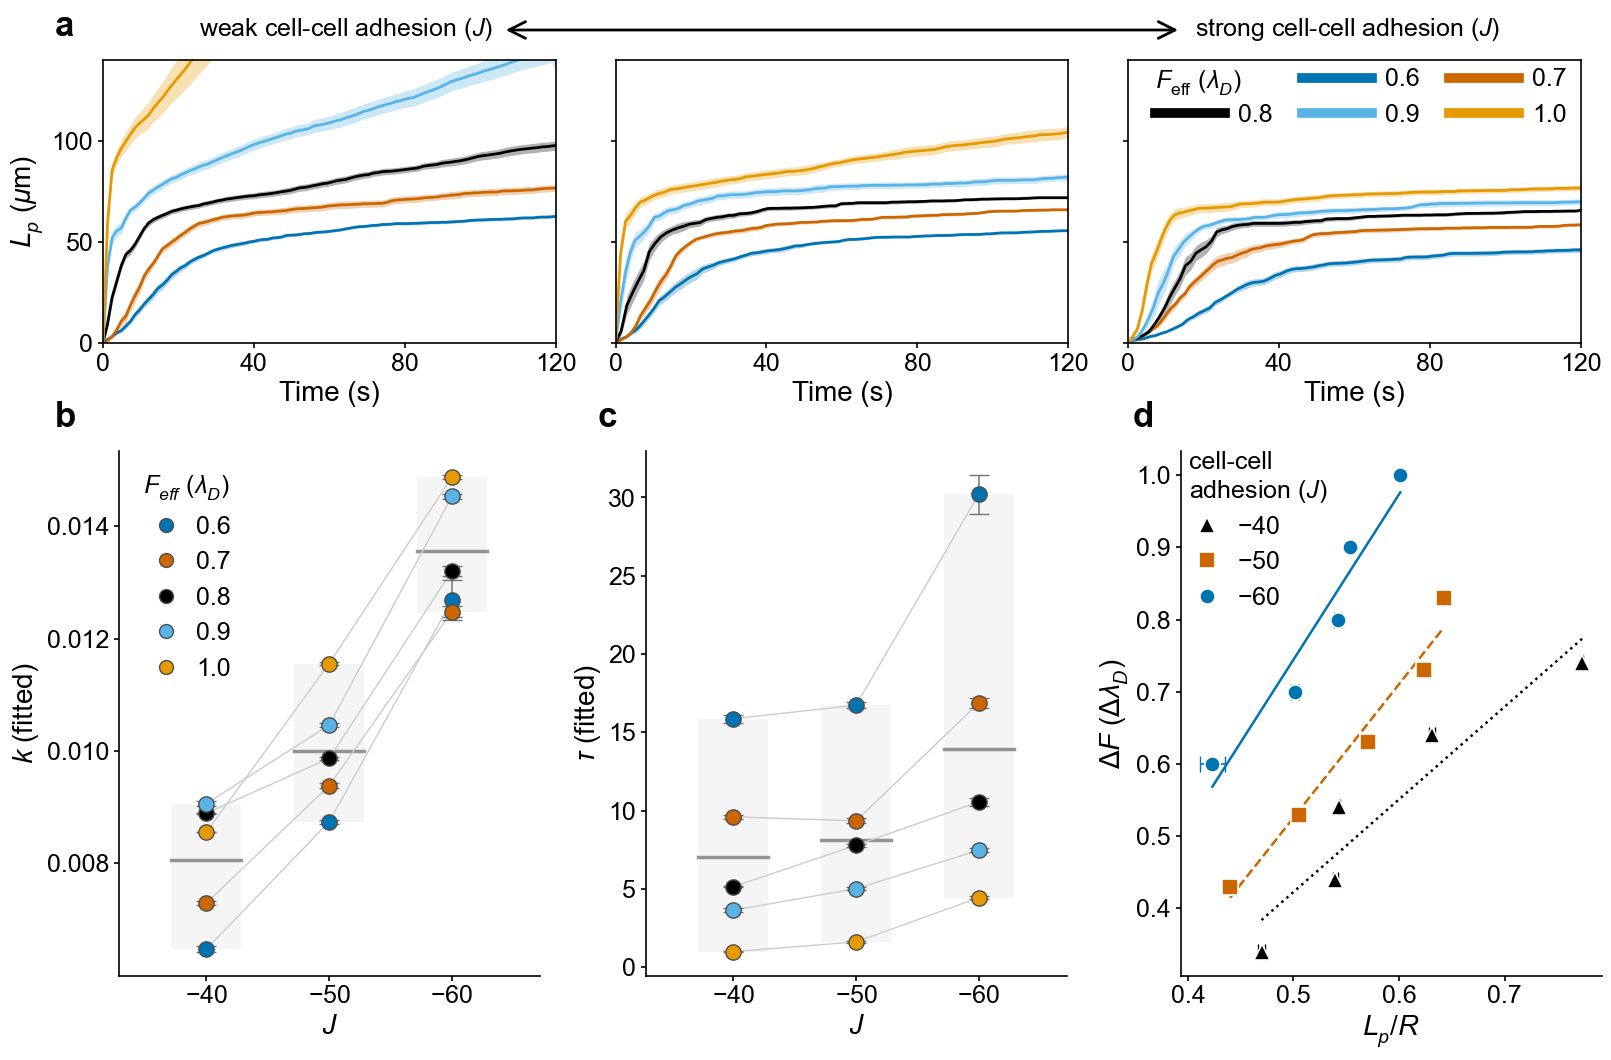

In [25]:
# ============================================================
# FIGURE LAYOUT
# Creates a 2-row figure:
# - Top row: 3 time-course plots (A, B, C)
# - Bottom row: 3 analysis plots (D, E, F)
# ============================================================

# Create figure with custom layout
fig = plt.figure(figsize=(16, 10), constrained_layout=True)

# Define 3-row grid with middle row as spacer
outer = fig.add_gridspec(
    3, 1,
    height_ratios=[1, 0.1, 1.7],  # top, spacer, bottom
    hspace=0.0
)

# Top row: three subplots with tight spacing
top = outer[0].subgridspec(1, 3, wspace=0.06)

# Bottom row: three subplots with equal widths
bottom = outer[2].subgridspec(
    1, 3,
    width_ratios=[1.0, 1.0, 1.0],
    wspace=0.06
)

# Fine-tune spacing
fig.set_constrained_layout_pads(wspace=0.16)

# Create subplot axes
axd = {
    'A': fig.add_subplot(top[0, 0]),
    'B': fig.add_subplot(top[0, 1]),
    'C': fig.add_subplot(top[0, 2]),
    'D': fig.add_subplot(bottom[0, 0]),
    'E': fig.add_subplot(bottom[0, 1]),
    'F': fig.add_subplot(bottom[0, 2]),
}

# Map plotting functions to panels
panel_functions = {
    'A': subplot_Lp40,
    'B': subplot_Lp50,
    'C': subplot_Lp60,
    'D': subplot_k_all,
    'E': subplot_tau_lambda,
    'F': subplot_elasticity,
}

# Generate all subplots
for panel_name, func in panel_functions.items():
    func(axd[panel_name])

# Hide redundant y-axis labels in top row
axd['B'].tick_params(labelleft=False)
axd['C'].tick_params(labelleft=False)

# Render to get accurate subplot positions
fig.canvas.draw()

# Add panel labels
bbox_A = axd['A'].get_position()
bbox_D = axd['D'].get_position()
bbox_E = axd['E'].get_position()
bbox_F = axd['F'].get_position()

# Top row: single label for entire group
fig.text(
    bbox_A.x0 - 0.03,
    bbox_A.y1 + 0.05,
    'a',
    fontsize=25,
    fontweight='bold',
    va='top',
    ha='left'
)

# Bottom row: individual labels
fig.text(
    bbox_A.x0 - 0.03,
    bbox_D.y1 + 0.05,
    'b',
    fontsize=25,
    fontweight='bold',
    va='top',
    ha='left'
)

fig.text(
    bbox_E.x0 - 0.03,
    bbox_E.y1 + 0.05,
    'c',
    fontsize=25,
    fontweight='bold',
    va='top',
    ha='left'
)

fig.text(
    bbox_F.x0 - 0.03,
    bbox_F.y1 + 0.05,
    'd',
    fontsize=25,
    fontweight='bold',
    va='top',
    ha='left'
)

# Get combined bounds of A–C in figure coordinates
bbox_left = axd['A'].get_position()
bbox_right = axd['C'].get_position()

x0 = bbox_left.x0+0.25
x1 = bbox_right.x1-0.25
y = bbox_left.y1 + 0.03   # adjust upward/downward if needed

# Double-headed arrow spanning A–C
arrow = FancyArrowPatch(
    (x0, y), (x1, y),
    transform=fig.transFigure,
    arrowstyle='<->',
    mutation_scale=30,
    linewidth=2,
    color='black',
    clip_on=False
)
fig.add_artist(arrow)

# Text at both ends
fig.text(
    x0-0.19, y-0.013,
    r"weak cell-cell adhesion ($J$)",
    ha='left',
    va='bottom',
    fontsize=18
)

fig.text(
    x1+0.2, y-0.013,
    r"strong cell-cell adhesion ($J$)",
    ha='right',
    va='bottom',
    fontsize=18
)

plt.show()